In [1]:

import pandas as pd

df = pd.read_csv("School_Data_CSV.csv", encoding="cp1252")

print(df.columns.tolist())


['emisno', 'centername', 'institution_name', 'centreno', 'quintile', 'ward_id', 'street_address', 'new_long', 'new_lat']


C:\Users\ksomp\AppData\Local\Temp\ipykernel_29048\2887613464.py:3: DtypeWarning: Columns (0,7) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("School_Data_CSV.csv", encoding="cp1252")


In [2]:
# Inspect the structure and data types
print(df.shape)


(199853, 9)


In [3]:
print(df.info())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 199853 entries, 0 to 199852
Data columns (total 9 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   emisno            199853 non-null  object 
 1   centername        193922 non-null  object 
 2   institution_name  133926 non-null  object 
 3   centreno          199823 non-null  object 
 4   quintile          197040 non-null  object 
 5   ward_id           199071 non-null  object 
 6   street_address    193150 non-null  object 
 7   new_long          167741 non-null  object 
 8   new_lat           84107 non-null   float64
dtypes: float64(1), object(8)
memory usage: 13.7+ MB
None


In [4]:
print(df.head())


      emisno                      centername            institution_name  \
0  200100005  ABERDEEN SECONDARY SCHOOL (20)   ABERDEEN SECONDARY SCHOOL   
1  200100012              ADELAIDE GYMNASIUM          ADELAIDE GYMNASIUM   
2  200100018   AEROVILLE(SOMERSET EAST) (20)  AEROVILLE SECONDARY SCHOOL   
3  200100019              Al Azhar Institute     AL-AZHAR PRIMARY SCHOOL   
4  200100021      ALEXANDER ROAD HIGH SCHOOL  ALEXANDER ROAD HIGH SCHOOL   

  centreno        quintile   ward_id  \
0  4201001               3  21001001   
1  4171044               4  21208001   
2  4201002               3  21002002   
3  4222001  NOT APPLICABLE  29500009   
4  4221002               5  29300007   

                                      street_address  new_long   new_lat  
0              10 PARLIAMENT STREET,  ABERDEEN, 6270  24.06183 -32.47385  
1                       WELSH STREET, ADELAIDE, 5760  26.29476 -32.71036  
2               PERSEVERANCE DR, SOMERSET EAST, 5850  25.60073 -32.74592  
3 

In [5]:
# Count missing values
print(df.isnull().sum().sort_values(ascending=False))



new_lat             115746
institution_name     65927
new_long             32112
street_address        6703
centername            5931
quintile              2813
ward_id                782
centreno                30
emisno                   0
dtype: int64


In [6]:
# Check duplicate records
print("Duplicate rows:", df.duplicated().sum())



Duplicate rows: 766


In [7]:
# Inspect the column names
print(df.columns.tolist())



['emisno', 'centername', 'institution_name', 'centreno', 'quintile', 'ward_id', 'street_address', 'new_long', 'new_lat']


In [8]:
# Inspect unique values in relevant categories
for col in ["province", "quintile", "ward"]:
    if col in df.columns:
        print(f"\n{col}:")
        print(df[col].value_counts(dropna=False).head(20))




quintile:
quintile
1                 49010
2                 40114
3                 32288
TO BE UPDATED     22300
NOT APPLICABLE    16049
5                 12916
4                 11429
Q1                 3760
Q2                 3211
Q3                 2961
NaN                2813
.                   936
Q4                  880
Q5                  835
NQ2                 281
To be updated        30
99                   14
UNKNOWN               9
NQ5                   6
NQ4                   4
Name: count, dtype: int64


In [9]:
# Check geographic coordinates, if these columns exist
if {"new_lat", "new_long"}.issubset(df.columns):
    print(df[["new_lat", "new_long"]].describe())
    print("Missing coordinates:",
          df[["new_lat", "new_long"]].isnull().any(axis=1).sum())
#(pandas, n.d.)

            new_lat
count  8.410700e+04
mean  -1.784736e+03
std    2.278134e+05
min   -3.055680e+07
25%   -3.099605e+01
50%   -2.864470e+01
75%   -2.614645e+01
max    3.399448e+01
Missing coordinates: 115748


In [10]:
# Inspect missing values and blank strings

missing_summary = pd.DataFrame({
    "Missing_Values": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().mean() * 100).round(2),
    "Blank_Strings": df.apply(
        lambda col: col.astype("string").str.strip().eq("").sum()
    )
})

print(missing_summary.sort_values(
    "Missing_Percentage", ascending=False
))

                  Missing_Values  Missing_Percentage  Blank_Strings
new_lat                   115746               57.92              0
institution_name           65927               32.99              0
new_long                   32112               16.07              0
street_address              6703                3.35              0
centername                  5931                2.97              0
quintile                    2813                1.41              0
ward_id                      782                0.39              0
centreno                      30                0.02              0
emisno                         0                0.00              0


In [11]:
# Check unique values in each column

for col in df.columns:
    print(f"\n{col}")
    print("Unique values:", df[col].nunique(dropna=True))
    print("Examples:")
    print(df[col].dropna().unique()[:10])


emisno
Unique values: 36733
Examples:
['200100005' '200100012' '200100018' '200100019' '200100021' '200100024'
 '200100030' '200100033' '200100037' '200100041']

centername
Unique values: 12063
Examples:
['ABERDEEN SECONDARY SCHOOL (20)' 'ADELAIDE GYMNASIUM'
 'AEROVILLE(SOMERSET EAST) (20)' 'Al Azhar Institute'
 'ALEXANDER ROAD HIGH SCHOOL' 'ALEXANDRIA HOERSKOOL (21)'
 'AMAJINGQI SECONDARY SCHOOL (17)' 'HOERSKOOL ANDREW RABIE'
 'ARCADIA SECONDARY SCHOOL (22)' 'ASHERVILLE SECONDARY SCHOOL (20)']

institution_name
Unique values: 51343
Examples:
['ABERDEEN SECONDARY SCHOOL' 'ADELAIDE GYMNASIUM'
 'AEROVILLE SECONDARY SCHOOL' 'AL-AZHAR PRIMARY SCHOOL'
 'ALEXANDER ROAD HIGH SCHOOL' 'ALEXANDRIA HIGH SCHOOL'
 'SIPHO CAMAGU HIGH SCHOOL' 'ANDREW RABIE HIGH SCHOOL'
 'ARCADIA SENIOR SECONDARY SCHOOL' 'ASHERVILLE PUBLIC SCHOOL']

centreno
Unique values: 10359
Examples:
['4201001' '4171044' '4201002' '4222001' '4221002' '4211001' '4171045'
 '4221026' '4221003' '4201003']

quintile
Unique values: 23

In [12]:
# Inspect repeated identifiers

for col in ["emisno", "centreno", "ward_id"]:
    print(f"\n{col}")
    print("Missing:", df[col].isna().sum())
    print("Unique:", df[col].nunique(dropna=True))
    print("Repeated non-missing values:",
          df[col].dropna().duplicated().sum())


emisno
Missing: 0
Unique: 36733
Repeated non-missing values: 163120

centreno
Missing: 30
Unique: 10359
Repeated non-missing values: 189464

ward_id
Missing: 782
Unique: 4857
Repeated non-missing values: 194214


In [13]:
# Inspect coordinates without changing the original columns

lat = pd.to_numeric(df["new_lat"], errors="coerce")

# Remove commas
# This also allows malformed coordinate strings to be flagged
# by the geographic range checks below.
long = pd.to_numeric(
    df["new_long"].astype("string")
      .str.replace(",", "", regex=False),
    errors="coerce"
)

# screening bounds for South Africa
valid_lat = lat.between(-35, -22)
valid_long = long.between(16, 33)

coordinate_summary = {
    "Latitude missing or non-numeric": int(lat.isna().sum()),
    "Longitude missing or non-numeric": int(long.isna().sum()),
    "Latitude outside approximate bounds": int(
        (lat.notna() & ~valid_lat).sum()
    ),
    "Longitude outside approximate bounds": int(
        (long.notna() & ~valid_long).sum()
    ),
    "Both coordinates within bounds": int(
        (valid_lat & valid_long).sum()
    ),
    "At least one coordinate missing or invalid": int(
        (~(valid_lat & valid_long)).sum()
    )
}

for issue, count in coordinate_summary.items():
    print(f"{issue}: {count}")

# Display coordinate records for manual investigation
suspect_coordinates = df.loc[
    lat.notna() & ~valid_lat
    | long.notna() & ~valid_long,
    ["emisno", "centername", "new_long", "new_lat"]
]

print(suspect_coordinates.head(20))
#(pandas, n.d.)

Latitude missing or non-numeric: 115746
Longitude missing or non-numeric: 39368
Latitude outside approximate bounds: 12
Longitude outside approximate bounds: 1151
Both coordinates within bounds: 84090
At least one coordinate missing or invalid: 115761
         emisno          centername    new_long  new_lat
2148  100000575                   .   -23.35724      NaN
2622  100000127                   .  118.677419      NaN
3385  200100007      NOT APPLICABLE          99      NaN
3387  200100010      NOT APPLICABLE          99      NaN
3388  200100011      NOT APPLICABLE          99      NaN
3398  200100022      NOT APPLICABLE          99      NaN
3423  200100063      NOT APPLICABLE          99      NaN
3432  200100074      NOT APPLICABLE          99      NaN
3441  200100090      NOT APPLICABLE          99      NaN
3445  200100095      NOT APPLICABLE          99      NaN
3537  200100224      NOT APPLICABLE          99      NaN
3979  200100924      NOT APPLICABLE          99      NaN
3984  2

In [14]:
# Inspect quintile values after diagnostic standardisation
# This does not change df["quintile"].

quintile_check = (
    df["quintile"]
    .astype("string")
    .str.strip()
    .str.upper()
    .value_counts(dropna=False)
)

print(quintile_check)

quintile
1                                                    49010
2                                                    40114
3                                                    32288
TO BE UPDATED                                        22330
NOT APPLICABLE                                       16049
5                                                    12916
4                                                    11429
Q1                                                    3760
Q2                                                    3211
Q3                                                    2961
<NA>                                                  2813
.                                                      936
Q4                                                     880
Q5                                                     835
NQ2                                                    281
99                                                      14
UNKNOWN                                        

In [15]:
# Inspect ward coverage

print("Number of unique wards:",
      df["ward_id"].nunique(dropna=True))

print("Records with missing ward:",
      df["ward_id"].isna().sum())

print("\nTop 20 wards by number of records:")

print(
    df["ward_id"]
    .value_counts()
    .head(20)
)

Number of unique wards: 4857
Records with missing ward: 782

Top 20 wards by number of records:
ward_id
TO BE UPDATED    12074
99                3661
.                 3482
3                 1033
6                  818
7                  750
2                  737
4                  730
5                  702
15                 629
1                  587
14                 543
11                 536
13                 525
12                 519
16                 501
17                 494
18                 493
8                  486
10                 445
Name: count, dtype: int64


In [16]:
# Inspect ward and quintile combinations

ward_quintile_counts = (
    df.dropna(subset=["ward_id", "quintile"])
      .groupby(["ward_id", "quintile"])
      .size()
      .reset_index(name="record_count")
)

print(ward_quintile_counts.head(20))
print("Number of ward-quintile combinations:",
      len(ward_quintile_counts))

   ward_id        quintile  record_count
0        .               .           442
1        .               1           926
2        .               2           523
3        .               3           363
4        .               4           122
5        .               5            86
6        .  NOT APPLICABLE          1020
7        0               1            12
8        0               2             9
9        0               3             4
10       0               4             5
11       0  NOT APPLICABLE            26
12       0              Q1             6
13       0              Q2             4
14       0              Q3             2
15       0              Q4             2
16       1               .            26
17       1               1           182
18       1               2           158
19       1               3           133
Number of ward-quintile combinations: 17850


In [17]:
# Check available variables against the research purpose

required_for_overcrowding = [
    "learner_enrolment",
    "classroom_count",
    "school_capacity"
]

for col in required_for_overcrowding:
    print(f"{col}: {'Available' if col in df.columns else 'Not available'}")

learner_enrolment: Not available
classroom_count: Not available
school_capacity: Not available


In [18]:
# Preserve the original DataFrame
df_raw = df.copy(deep=True)

# Create a separate working DataFrame
df_clean = df_raw.copy(deep=True)

# Record the baseline
print("Original rows:", len(df_raw))
print("Original columns:", len(df_raw.columns))
print("Original exact duplicate rows:", df_raw.duplicated().sum())

# Check whether the copy matches the original
print("Working copy matches original:", df_clean.equals(df_raw))

Original rows: 199853
Original columns: 9
Original exact duplicate rows: 766
Working copy matches original: True


In [19]:
# Standardise text formatting without deleting records

text_columns = df_clean.select_dtypes(
    include=["object", "string"]
).columns

for col in text_columns:
    df_clean[col] = df_clean[col].astype("string").str.strip()
    df_clean[col] = df_clean[col].replace("", pd.NA)

print("Rows after text standardisation:", len(df_clean))
print("\nMissing values after standardisation:")
print(df_clean.isna().sum().sort_values(ascending=False))
#(pandas, n.d.)

Rows after text standardisation: 199853

Missing values after standardisation:
new_lat             115746
institution_name     65927
new_long             32112
street_address        6703
centername            5931
quintile              2813
ward_id                782
centreno                30
emisno                   0
dtype: int64


In [20]:
# Standardise quintile labels

df_clean["quintile_original"] = df_clean["quintile"]

df_clean["quintile_clean"] = (
    df_clean["quintile"]
    .astype("string")
    .str.strip()
    .str.upper()
)

# Combine equivalent looking labels
quintile_mapping = {
    "1": "Q1",
    "2": "Q2",
    "3": "Q3",
    "4": "Q4",
    "5": "Q5"
}

df_clean["quintile_clean"] = (
    df_clean["quintile_clean"].replace(quintile_mapping)
)

print(df_clean["quintile_clean"].value_counts(dropna=False))

quintile_clean
Q1                                                   52770
Q2                                                   43325
Q3                                                   35249
TO BE UPDATED                                        22330
NOT APPLICABLE                                       16049
Q5                                                   13751
Q4                                                   12309
<NA>                                                  2813
.                                                      936
NQ2                                                    281
99                                                      14
UNKNOWN                                                  9
NQ5                                                      6
NQ4                                                      4
27.19015                                                 2
NQ1                                                      2
NQ3                                      

In [21]:
# Create a standardised ward field

df_clean["ward_id_original"] = df_clean["ward_id"]

df_clean["ward_id_clean"] = (
    df_clean["ward_id"]
    .astype("string")
    .str.strip()
    .str.upper()
)

# Clearly nonidentifier text placeholders
invalid_ward_labels = [
    "TO BE UPDATED",
    ".",
    "UNKNOWN",
    "NOT APPLICABLE"
]

df_clean["ward_id_clean"] = (
    df_clean["ward_id_clean"].replace(invalid_ward_labels, pd.NA)
)

print("Ward values after initial standardisation:")
print(df_clean["ward_id_clean"].value_counts(dropna=False).head(20))

print("\nMissing or flagged ward values:",
      df_clean["ward_id_clean"].isna().sum())

Ward values after initial standardisation:
ward_id_clean
<NA>    16338
99       3661
3        1033
6         818
7         750
2         737
4         730
5         702
15        629
1         587
14        543
11        536
13        525
12        519
16        501
17        494
18        493
8         486
10        445
19        427
Name: count, dtype: Int64

Missing or flagged ward values: 16338


In [22]:
# Investigate longitude formats

comma_values = df_clean.loc[
    df_clean["new_long"].astype("string").str.contains(",", na=False),
    ["emisno", "centername", "new_long", "new_lat"]
]

print("Longitude values containing commas:", len(comma_values))
print(comma_values.head(30).to_string(index=False))

Longitude values containing commas: 5
   emisno                     centername    new_long  new_lat
200200181                 CANAAN ACADEMY -33,031,497      NaN
200200310                    East London -32,967,171      NaN
200201078             Kings College (18)  -3,301,629      NaN
200501593                 NOT APPLICABLE -31,369,457      NaN
200601181 GET AHEAD COLLEGE (QUEENSTOWN) -31,909,928      NaN


In [23]:
# Convert coordinates to numeric values

df_clean["latitude_clean"] = pd.to_numeric(
    df_clean["new_lat"], errors="coerce"
)

# Do not remove commas inspect them first
df_clean["longitude_clean"] = pd.to_numeric(
    df_clean["new_long"], errors="coerce"
)

# screening bounds for South Africa
valid_latitude = df_clean["latitude_clean"].between(-35, -22)
valid_longitude = df_clean["longitude_clean"].between(16, 33)

valid_coordinates = valid_latitude & valid_longitude

print("Valid coordinate pairs:", int(valid_coordinates.sum()))
print("Missing or invalid coordinate pairs:",
      int((~valid_coordinates).sum()))

print("Latitude outside bounds:",
      int((df_clean["latitude_clean"].notna()
           & ~valid_latitude).sum()))

print("Longitude outside bounds:",
      int((df_clean["longitude_clean"].notna()
           & ~valid_longitude).sum()))

Valid coordinate pairs: 84090
Missing or invalid coordinate pairs: 115761
Latitude outside bounds: 12
Longitude outside bounds: 1146


In [24]:
# Examine duplicate records

print("Exact duplicate rows:", df_clean.duplicated().sum())

print("\nExample exact duplicates:")
print(
    df_clean.loc[
        df_clean.duplicated(keep=False)
    ].sort_values("emisno").head(20).to_string(index=False)
)

print("\nRepeated EMIS numbers:")
print(
    df_clean["emisno"].value_counts().head(15)
)

Exact duplicate rows: 799

Example exact duplicates:
   emisno     centername institution_name centreno       quintile       ward_id                             street_address  new_long    new_lat quintile_original quintile_clean ward_id_original ward_id_clean  latitude_clean  longitude_clean
100000286  FOCUS COLLEGE             <NA>  1369986  TO BE UPDATED      19100062                                       <NA> 18.468418 -34.006730     TO BE UPDATED  TO BE UPDATED         19100062      19100062      -34.006730        18.468418
100000286  FOCUS COLLEGE             <NA>  1369986  TO BE UPDATED      19100062                                       <NA> 18.468418 -34.006730     TO BE UPDATED  TO BE UPDATED         19100062      19100062      -34.006730        18.468418
101008377 NOT APPLICABLE             <NA>       99  TO BE UPDATED      10204004                                       <NA> 18.614949 -33.916178     TO BE UPDATED  TO BE UPDATED         10204004      10204004      -33.916178 

In [25]:
# Review the working dataset

print("Original row count:", len(df_raw))
print("Current row count:", len(df_clean))
print("Current columns:", df_clean.shape[1])

print("\nMissing values:")
print(df_clean.isna().sum().sort_values(ascending=False))

print("\nQuintile distribution:")
print(df_clean["quintile_clean"].value_counts(dropna=False))

print("\nExact duplicate rows:", df_clean.duplicated().sum())

print("\nValid coordinate pairs:", int(valid_coordinates.sum()))

Original row count: 199853
Current row count: 199853
Current columns: 15

Missing values:
new_lat              115746
latitude_clean       115746
institution_name      65927
longitude_clean       39373
new_long              32112
ward_id_clean         16338
street_address         6703
centername             5931
quintile               2813
quintile_original      2813
quintile_clean         2813
ward_id                 782
ward_id_original        782
centreno                 30
emisno                    0
dtype: int64

Quintile distribution:
quintile_clean
Q1                                                   52770
Q2                                                   43325
Q3                                                   35249
TO BE UPDATED                                        22330
NOT APPLICABLE                                       16049
Q5                                                   13751
Q4                                                   12309
<NA>                     

In [26]:
# Compare duplicates using only the original nine columns
original_columns = df_raw.columns.tolist()

print("Duplicates in original data:", df_raw.duplicated().sum())

print(
    "Duplicates after text standardisation:",
    df_clean.duplicated(subset=original_columns).sum()
)

# Inspect records that are duplicates after standardisation
new_duplicate_examples = df_clean.loc[
    df_clean.duplicated(subset=original_columns, keep=False),
    original_columns
]

print(new_duplicate_examples.head(20).to_string(index=False))

Duplicates in original data: 766
Duplicates after text standardisation: 799
   emisno                       centername                 institution_name centreno quintile  ward_id                                                     street_address    new_long  new_lat
700111112          NALEDI SECONDARY SCHOOL          NALEDI SECONDARY SCHOOL  8111112        4 79800020                                     378 NAPE, NALEDI, SOWETO, 1867 27.83081497      NaN
700111195         PRUDENS SECONDARY SCHOOL         PRUDENS SECONDARY SCHOOL  8111195        3 79800021                                   636 LEGWALE, TLADI, SOWETO, 1868 27.84465333      NaN
700111203         REASOMA SECONDARY SCHOOL         REASOMA SECONDARY SCHOOL  8111203        5 79800014                      2001 NTLOKO STREET, PROTEA GLEN, SOWETO, 1818    27.83656      NaN
700111252    SEKANONTOANE SECONDARY SCHOOL    SEKANONTOANE SECONDARY SCHOOL  8111252        4 79800015                       1926 MABALANE STREET, SENAOANE, SOW

In [27]:
df_clean = df_clean.drop_duplicates(
    subset=original_columns
).copy()

print("Rows after removing confirmed exact duplicates:", len(df_clean))
print(
    "Remaining exact duplicates:",
    df_clean.duplicated(subset=original_columns).sum()
)

Rows after removing confirmed exact duplicates: 199054
Remaining exact duplicates: 0


In [28]:
df_q7 = df_clean.copy()

# Keep only recognised Q1-Q5 labels for the quintile plots.
# Other categories remain in df_q7 but are excluded from these plots.
valid_quintiles = ["Q1", "Q2", "Q3", "Q4", "Q5"]

df_q7["quintile_plot"] = df_q7["quintile_clean"].where(
    df_q7["quintile_clean"].isin(valid_quintiles)
)

print("Records in recognised quintiles:",
      df_q7["quintile_plot"].notna().sum())

print("\nRecords excluded from quintile plots:",
      df_q7["quintile_plot"].isna().sum())

print("\nQuintile counts:")
print(df_q7["quintile_plot"].value_counts().sort_index())

Records in recognised quintiles: 156874

Records excluded from quintile plots: 42180

Quintile counts:
quintile_plot
Q1    52626
Q2    43207
Q3    35131
Q4    12236
Q5    13674
Name: count, dtype: Int64


In [29]:
print(
    df_q7["ward_id_clean"]
    .dropna()
    .astype("string")
    .str.len()
    .value_counts()
    .sort_index()
)

ward_id_clean
1      6339
2     13416
3        15
8    162994
9         1
Name: count, dtype: Int64


In [30]:
df_q7_geo = df_q7.loc[
    df_q7["latitude_clean"].between(-35, -22)
    & df_q7["longitude_clean"].between(16, 33)
].copy()

print("Records available for geographic scatter plot:", len(df_q7_geo))
print(df_q7_geo[["longitude_clean", "latitude_clean"]].describe())

Records available for geographic scatter plot: 83619
       longitude_clean  latitude_clean
count          83619.0    83619.000000
mean         28.313273      -28.625791
std           3.110657        3.053714
min           16.48461      -34.821641
25%          27.388643      -31.004810
50%            28.9322      -28.663400
75%          30.446337      -26.150495
max            32.8679      -22.194810


In [31]:
#claude by anthropic ai
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------- Settings ----------
OUTPUT_DIR = Path("figures")
OUTPUT_DIR.mkdir(exist_ok=True)
DPI = 300

VALID_QUINTILES = ["Q1", "Q2", "Q3", "Q4", "Q5"]
LAT_BOUNDS = (-35, -22)      # screening bounds only, not proof of correctness
LON_BOUNDS = (16, 33)

# Colour-blind-friendly colours, one per quintile
QUINTILE_COLOURS = {
    "Q1": "#d73027", "Q2": "#fc8d59", "Q3": "#999999",
    "Q4": "#91bfdb", "Q5": "#4575b4",
}

TOP_N_WARDS = 25             # number of wards shown in Visualisation 1
ALLOWED_WARD_LENGTHS = None  # e.g. {8} to keep only 8-digit IDs; None keeps all

# ---------- Check required columns ----------
required_cols = ["emisno", "quintile_clean", "ward_id_clean",
                 "latitude_clean", "longitude_clean", "new_lat", "new_long"]
missing_cols = [c for c in required_cols if c not in df_clean.columns]
if missing_cols:
    raise KeyError(f"df_clean is missing required columns: {missing_cols}")

# ---------- Separate working copy (df_clean is never modified) ----------
base = df_clean[required_cols].copy()

# --- Quintile: keep only Q1-Q5; everything else becomes NaN, with a reason ---
q_raw = base["quintile_clean"].astype("string").str.strip().str.upper()
base["quintile_std"] = q_raw.where(q_raw.isin(VALID_QUINTILES))

# Plain NumPy boolean arrays (NA treated as False) so np.where/np.select work safely
is_recognised = base["quintile_std"].notna().to_numpy(dtype=bool)
is_blank = (q_raw.isna() | (q_raw == "")).fillna(True).to_numpy(dtype=bool)

base["quintile_status"] = np.select(
    [is_recognised, is_blank],
    ["Recognised (Q1-Q5)", "Missing"],
    default="Non-standard label",
)

# --- Ward ID: text, strip whitespace, remove only a trailing '.0' float artefact ---
w = base["ward_id_clean"].astype("string").str.strip()
w = w.str.replace(r"^(\d+)\.0$", r"\1", regex=True)
w = w.where(w.notna() & (w != "") & (w.str.lower() != "nan"))
base["ward_str"] = w
base["ward_len"] = base["ward_str"].str.len()
base["ward_is_digits"] = base["ward_str"].str.fullmatch(r"\d+").fillna(False)

# --- Coordinates: numeric conversion and bounds check ---
# Convert to plain float64 (NaN for missing/non-numeric) to avoid nullable-dtype issues
lat = pd.to_numeric(base["latitude_clean"], errors="coerce").astype("float64")
lon = pd.to_numeric(base["longitude_clean"], errors="coerce").astype("float64")

# Was a raw value supplied at all? (NA treated as "not present")
raw_lat_present = (base["new_lat"].astype("string").str.strip().fillna("") != "").to_numpy(dtype=bool)
raw_lon_present = (base["new_long"].astype("string").str.strip().fillna("") != "").to_numpy(dtype=bool)

# Plain NumPy boolean arrays for np.select
lat_ok = lat.notna().to_numpy(dtype=bool)
lon_ok = lon.notna().to_numpy(dtype=bool)
in_bounds = (lat.between(*LAT_BOUNDS) & lon.between(*LON_BOUNDS)).to_numpy(dtype=bool)

base["coord_status"] = np.select(
    [
        in_bounds,                                   # numeric and within bounds
        lat_ok & lon_ok,                             # numeric but outside bounds
        (~raw_lat_present) | (~raw_lon_present),     # raw value absent
    ],
    ["Valid (within bounds)", "Outside screening bounds", "Missing"],
    default="Non-numeric (could not convert)",
)
base["lat"], base["lon"] = lat, lon

# ---------- Print validation summaries ----------
print(f"Total records in df_clean: {len(base):,}")
print(f"Distinct emisno values:    {base['emisno'].nunique(dropna=True):,} "
      "(rows may not equal unique schools)\n")

print("Quintile status:")
print(base["quintile_status"].value_counts(dropna=False).to_string(), "\n")

nonstd = q_raw[base["quintile_status"] == "Non-standard label"].value_counts()
print("Non-standard quintile labels (top 15):")
print(nonstd.head(15).to_string() if len(nonstd) else "None", "\n")

print("Ward ID length distribution (missing shown as <NA>):")
print(base["ward_len"].value_counts(dropna=False).sort_index().to_string(), "\n")
print(f"Ward IDs containing non-digit characters: "
      f"{(base['ward_str'].notna() & ~base['ward_is_digits']).sum():,}\n")

print("Coordinate status:")
print(base["coord_status"].value_counts().to_string(), "\n")

def save_fig(fig, filename):
    """Save a figure as a high-resolution PNG and report the path."""
    path = OUTPUT_DIR / filename
    fig.savefig(path, dpi=DPI, bbox_inches="tight", facecolor="white")
    print(f"Saved: {path.resolve()}")

Total records in df_clean: 199,054
Distinct emisno values:    33,670 (rows may not equal unique schools)

Quintile status:
quintile_status
Recognised (Q1-Q5)    156874
Non-standard label     39381
Missing                 2799 

Non-standard quintile labels (top 15):
quintile_clean
TO BE UPDATED                                        22155
NOT APPLICABLE                                       15970
.                                                      936
NQ2                                                    281
99                                                      14
UNKNOWN                                                  9
NQ5                                                      6
NQ4                                                      4
NQ3                                                      2
NQ1                                                      2
27.19015                                                 1
3814 MOEDING STREET, MONYAKENG, WESSELSBRON, 9680        1 

Ward ID 

Visualisation 1: exclusions
  Starting records:                       199,054
  Excluded, missing/unusable ward ID:     16,289
  Excluded, ward-length validation:       0
  Excluded, missing/non-standard quintile:28,973
  Records used:                           153,792

Wards with at least one usable record: 4,795
Summary of total records per ward:
count    4795.00
mean       32.07
std        53.23
min         1.00
25%        11.00
50%        22.00
75%        42.00
max      2044.00 

Top 25 wards by total records (sorted by ward ID):
quintile_std   Q1   Q2   Q3   Q4   Q5  total
ward_str                                    
1             189  162  137   45   14    547
10            146   84  131   29   33    423
11            227  123  120   41    9    520
12            212  157   91   14   34    508
13            205  129  117   36    8    495
14            183  132  118   39   49    521
15            280  106  115   60   43    604
16            221   58  118   31   41    469
17        

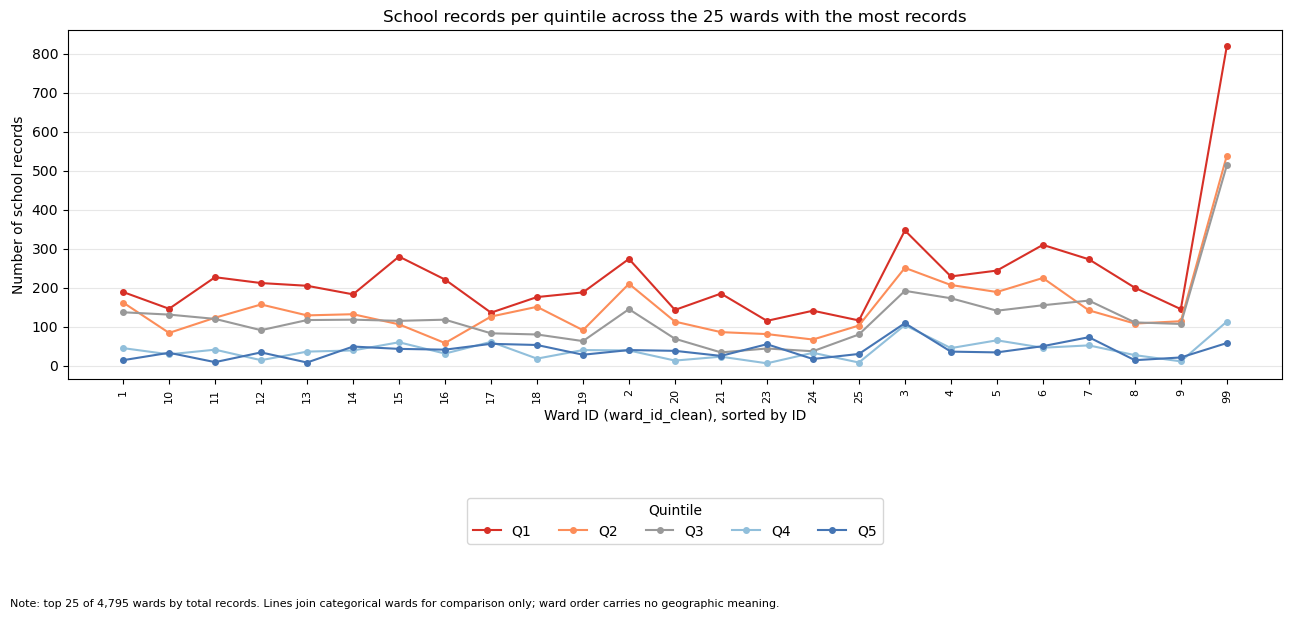

In [32]:
# ---------- Build the dataset for Visualisation 1 ----------
v1 = base.copy()
n_start = len(v1)

excl_ward_missing = v1["ward_str"].isna().sum()
v1 = v1[v1["ward_str"].notna()]

# Optional transparent ward validation (off by default)
excl_ward_len = 0
if ALLOWED_WARD_LENGTHS is not None:
    keep = v1["ward_len"].isin(ALLOWED_WARD_LENGTHS) & v1["ward_is_digits"]
    excl_ward_len = (~keep).sum()
    v1 = v1[keep]

excl_quintile = v1["quintile_std"].isna().sum()
v1 = v1[v1["quintile_std"].notna()]

print("Visualisation 1: exclusions")
print(f"  Starting records:                       {n_start:,}")
print(f"  Excluded, missing/unusable ward ID:     {excl_ward_missing:,}")
print(f"  Excluded, ward-length validation:       {excl_ward_len:,}")
print(f"  Excluded, missing/non-standard quintile:{excl_quintile:,}")
print(f"  Records used:                           {len(v1):,}\n")

if v1.empty:
    print("No records available for Visualisation 1; skipping plot.")
else:
    # Count records per ward-quintile combination
    counts = (v1.groupby(["ward_str", "quintile_std"]).size()
                .unstack("quintile_std", fill_value=0)
                .reindex(columns=VALID_QUINTILES, fill_value=0))
    counts["total"] = counts.sum(axis=1)

    print(f"Wards with at least one usable record: {len(counts):,}")
    print("Summary of total records per ward:")
    print(counts["total"].describe().round(2).to_string(), "\n")

    # Keep the wards with the highest totals, then sort IDs consistently
    top = counts.nlargest(TOP_N_WARDS, "total").sort_index()
    print(f"Top {len(top)} wards by total records (sorted by ward ID):")
    print(top.to_string(), "\n")

    covered = top["total"].sum() / counts["total"].sum() * 100
    print(f"These wards hold {covered:.1f}% of the usable records.")

    # ---------- Plot ----------
    fig, ax = plt.subplots(figsize=(13, 6))
    x = np.arange(len(top))
    for q in VALID_QUINTILES:
        ax.plot(x, top[q].values, marker="o", markersize=4, linewidth=1.5,
                color=QUINTILE_COLOURS[q], label=q)

    ax.set_xticks(x)
    ax.set_xticklabels(top.index, rotation=90, fontsize=8)
    ax.set_xlabel("Ward ID (ward_id_clean), sorted by ID")
    ax.set_ylabel("Number of school records")
    ax.set_title(f"School records per quintile across the {len(top)} wards "
                 f"with the most records")
    ax.legend(title="Quintile", ncol=5, loc="upper center",
              bbox_to_anchor=(0.5, -0.32))
    ax.grid(axis="y", alpha=0.3)
    fig.text(0.01, -0.02,
             f"Note: top {len(top)} of {len(counts):,} wards by total records. "
             "Lines join categorical wards for comparison only; ward order carries no geographic meaning.",
             fontsize=8, ha="left")
    fig.tight_layout()
    save_fig(fig, "viz1_line_records_per_ward_by_quintile.png")
    plt.show()

Visualisation 2: coordinate screening
coord_status
Missing                     115420
Valid (within bounds)        83619
Outside screening bounds        15
  (Bounds: latitude (-35, -22), longitude (16, 33))

Quintile status among rows with valid coordinates:
quintile_status
Recognised (Q1-Q5)    61957
Non-standard label    21500
Missing                 162 

Records plotted (valid coordinates and Q1-Q5): 61,957
Valid-coordinate records not plotted (missing/non-standard quintile): 21,662

Plotted records per quintile:
quintile_std
Q1    21059
Q2    17338
Q3    13844
Q4     4556
Q5     5160
Saved: C:\Users\ksomp\Documents\campus stuff\sem 2\DASC8412\A2\code\figures\viz2_scatter_school_coordinates_by_quintile.png


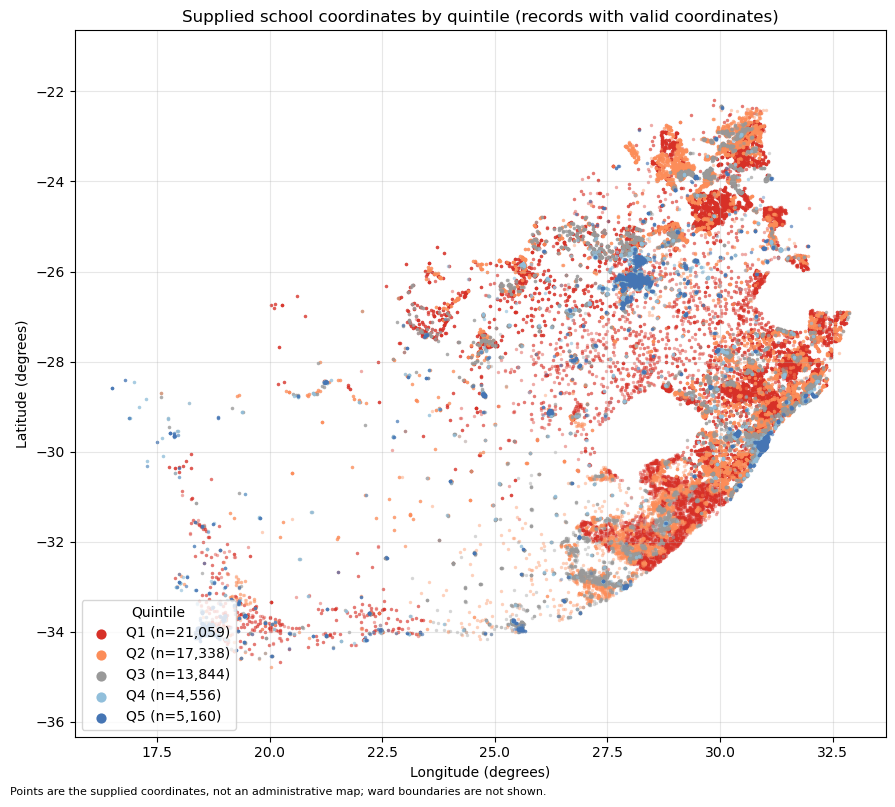

In [33]:
# ---------- Coordinate exclusion report ----------
print("Visualisation 2: coordinate screening")
print(base["coord_status"].value_counts().to_string())
print(f"  (Bounds: latitude {LAT_BOUNDS}, longitude {LON_BOUNDS})\n")

v2_valid = base[base["coord_status"] == "Valid (within bounds)"].copy()

# Quintile handling among valid-coordinate rows
print("Quintile status among rows with valid coordinates:")
print(v2_valid["quintile_status"].value_counts().to_string(), "\n")

v2 = v2_valid[v2_valid["quintile_std"].notna()].copy()
print(f"Records plotted (valid coordinates and Q1-Q5): {len(v2):,}")
print(f"Valid-coordinate records not plotted (missing/non-standard quintile): "
      f"{len(v2_valid) - len(v2):,}\n")

if v2.empty:
    print("No records with valid coordinates and a recognised quintile; skipping plot.")
else:
    print("Plotted records per quintile:")
    print(v2["quintile_std"].value_counts().reindex(VALID_QUINTILES, fill_value=0).to_string())

    # Shuffle so no single quintile systematically hides the others
    v2 = v2.sample(frac=1, random_state=42)

    fig, ax = plt.subplots(figsize=(9, 8))
    for q in VALID_QUINTILES:
        sub = v2[v2["quintile_std"] == q]
        if sub.empty:
            continue
        ax.scatter(sub["lon"], sub["lat"], s=6, alpha=0.4, linewidths=0,
                   color=QUINTILE_COLOURS[q], label=f"{q} (n={len(sub):,})",
                   rasterized=True)

    ax.set_xlabel("Longitude (degrees)")
    ax.set_ylabel("Latitude (degrees)")
    ax.set_title("Supplied school coordinates by quintile (records with valid coordinates)")
    ax.set_aspect("equal", adjustable="datalim")
    ax.grid(alpha=0.3)
    leg = ax.legend(title="Quintile", markerscale=3, loc="lower left")
    for h in leg.legend_handles:
        h.set_alpha(1)
    fig.text(0.01, 0.0,
             "Points are the supplied coordinates, not an administrative map; ward boundaries are not shown.",
             fontsize=8)
    fig.tight_layout()
    save_fig(fig, "viz2_scatter_school_coordinates_by_quintile.png")
    plt.show()

Quintile handling (all records):
quintile_status
Recognised (Q1-Q5)    156874
Non-standard label     39381
Missing                 2799 

Quintile frequency table:
              count  pct_of_recognised  pct_of_all_records
quintile_std                                              
Q1            52626              33.55               26.44
Q2            43207              27.54               21.71
Q3            35131              22.39               17.65
Q4            12236                7.8                6.15
Q5            13674               8.72                6.87

Recognised: 156,874 of 199,054 records (78.8%). Missing and non-standard labels are excluded from the bars.

Saved: C:\Users\ksomp\Documents\campus stuff\sem 2\DASC8412\A2\code\figures\viz3a_histogram_style_quintile_distribution.png


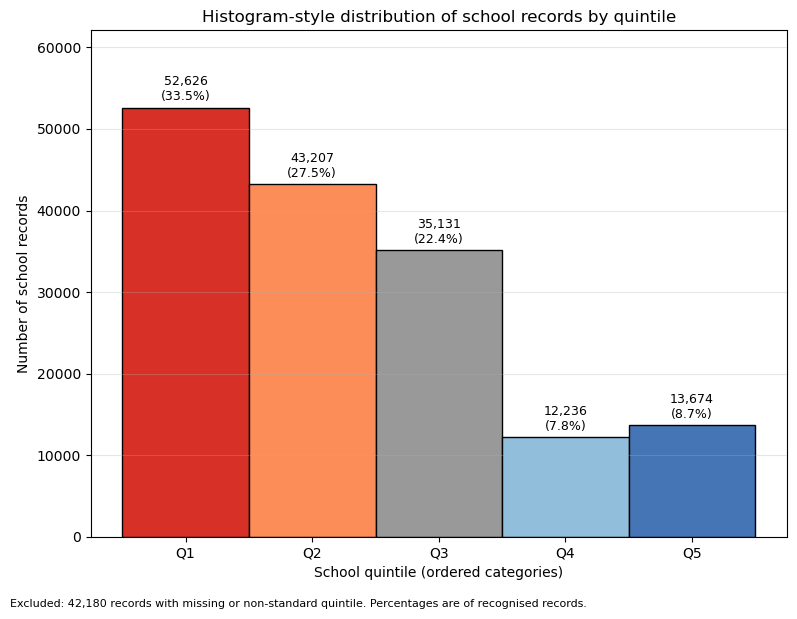

Saved: C:\Users\ksomp\Documents\campus stuff\sem 2\DASC8412\A2\code\figures\viz3b_bar_chart_quintile_counts.png


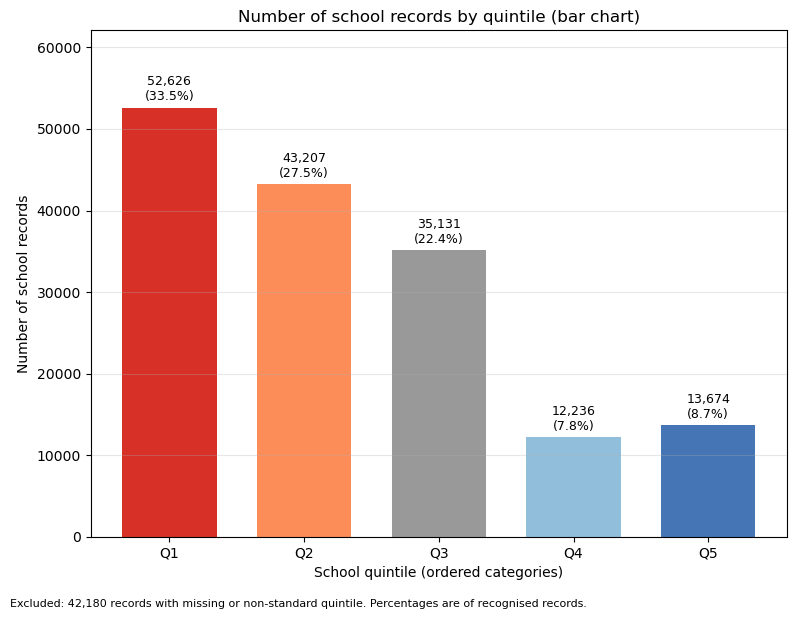

In [34]:
# ---------- Counts and percentages ----------
v3 = base[["quintile_std", "quintile_status"]].copy()
n_all = len(v3)

print("Quintile handling (all records):")
print(v3["quintile_status"].value_counts().to_string(), "\n")

recognised = v3[v3["quintile_std"].notna()]
if recognised.empty:
    print("No recognised quintile values; skipping Visualisation 3.")
else:
    freq = (recognised["quintile_std"].value_counts()
            .reindex(VALID_QUINTILES, fill_value=0).rename("count").to_frame())
    freq["pct_of_recognised"] = freq["count"] / freq["count"].sum() * 100
    freq["pct_of_all_records"] = freq["count"] / n_all * 100
    print("Quintile frequency table:")
    print(freq.round(2).to_string())
    print(f"\nRecognised: {freq['count'].sum():,} of {n_all:,} records "
          f"({freq['count'].sum() / n_all * 100:.1f}%). "
          "Missing and non-standard labels are excluded from the bars.\n")

    excluded_n = n_all - freq["count"].sum()
    note = (f"Excluded: {excluded_n:,} records with missing or non-standard quintile. "
            "Percentages are of recognised records.")

    def draw_bars(ax, width, edgecolor):
        bars = ax.bar(freq.index, freq["count"], width=width,
                      color=[QUINTILE_COLOURS[q] for q in freq.index],
                      edgecolor=edgecolor)
        for bar, (_, row) in zip(bars, freq.iterrows()):
            ax.annotate(f"{int(row['count']):,}\n({row['pct_of_recognised']:.1f}%)",
                        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                        ha="center", va="bottom", fontsize=9,
                        xytext=(0, 3), textcoords="offset points")
        ax.set_xlabel("School quintile (ordered categories)")
        ax.set_ylabel("Number of school records")
        ax.set_ylim(0, freq["count"].max() * 1.18)
        ax.grid(axis="y", alpha=0.3)

    # ---- 3a: histogram-style (touching bars, as requested) ----
    fig, ax = plt.subplots(figsize=(8, 6))
    draw_bars(ax, width=1.0, edgecolor="black")
    ax.set_title("Histogram-style distribution of school records by quintile")
    fig.text(0.01, -0.02, note, fontsize=8)
    fig.tight_layout()
    save_fig(fig, "viz3a_histogram_style_quintile_distribution.png")
    plt.show()

    # ---- 3b: supplementary bar chart (separated bars, categorical) ----
    fig, ax = plt.subplots(figsize=(8, 6))
    draw_bars(ax, width=0.7, edgecolor="none")
    ax.set_title("Number of school records by quintile (bar chart)")
    fig.text(0.01, -0.02, note, fontsize=8)
    fig.tight_layout()
    save_fig(fig, "viz3b_bar_chart_quintile_counts.png")
    plt.show()

In [35]:
#chatgpt by openai
# ============================================================
# SECTION 2: IMPORTS AND DATA VALIDATION
# ============================================================

import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from matplotlib.lines import Line2D

# ------------------------------------------------------------
# 1. Confirm that df_clean already exists
# ------------------------------------------------------------

if "df_clean" not in globals():
    raise NameError(
        "df_clean was not found. Run your data-cleaning notebook "
        "cells before running this analysis."
    )

if not isinstance(df_clean, pd.DataFrame):
    raise TypeError("df_clean must be a pandas DataFrame.")

# ------------------------------------------------------------
# 2. Define the columns required for the analysis
# ------------------------------------------------------------

required_columns = [
    "quintile_clean",
    "ward_id_clean",
    "latitude_clean",
    "longitude_clean"
]

missing_columns = [
    column for column in required_columns
    if column not in df_clean.columns
]

if missing_columns:
    raise KeyError(
        f"Required columns are missing: {missing_columns}\n"
        f"Available columns: {df_clean.columns.tolist()}"
    )

# Create a separate working copy.
# The original df_clean will not be modified.
df_viz = df_clean.copy(deep=True)

# Use a dedicated output directory for assignment figures.
OUTPUT_DIR = Path("school_visualisation_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Recognised quintile categories and their consistent order.
QUINTILES = ["Q1", "Q2", "Q3", "Q4", "Q5"]

# South African coordinate screening bounds.
LAT_MIN, LAT_MAX = -35, -22
LON_MIN, LON_MAX = 16, 33

# Visualisation 1: number of wards displayed.
# Increase this value to show more wards.
TOP_N_WARDS = 25

# ------------------------------------------------------------
# 3. Basic dataset information
# ------------------------------------------------------------

print("=" * 65)
print("DATASET OVERVIEW")
print("=" * 65)

print(f"Number of records: {len(df_viz):,}")
print(f"Number of columns: {df_viz.shape[1]:,}")

print("\nColumn data types:")
print(df_viz[required_columns].dtypes)

print("\nMissing values in required columns:")
print(
    df_viz[required_columns]
    .isna()
    .sum()
    .rename("missing_count")
    .to_frame()
)

# ------------------------------------------------------------
# 4. Examine quintile values
# ------------------------------------------------------------

# Convert labels to strings for inspection without changing df_clean.
# Whitespace is removed and labels are standardised to uppercase.
quintile_text = (
    df_viz["quintile_clean"]
    .astype("string")
    .str.strip()
    .str.upper()
)

# Treat blank strings as missing for this analysis.
quintile_text = quintile_text.replace("", pd.NA)

recognised_quintile_mask = quintile_text.isin(QUINTILES)

print("\n" + "=" * 65)
print("QUINTILE DATA QUALITY")
print("=" * 65)

print(
    f"Records with recognised Q1-Q5 labels: "
    f"{recognised_quintile_mask.sum():,}"
)

print(
    f"Records with missing or non-standard quintile labels: "
    f"{(~recognised_quintile_mask).sum():,}"
)

print("\nMost frequent quintile values, including non-standard labels:")

print(
    quintile_text
    .value_counts(dropna=False)
    .head(20)
    .to_frame("record_count")
)

# ------------------------------------------------------------
# 5. Examine ward identifier values
# ------------------------------------------------------------

ward_text = (
    df_viz["ward_id_clean"]
    .astype("string")
    .str.strip()
)

ward_text = ward_text.replace("", pd.NA)

print("\n" + "=" * 65)
print("WARD IDENTIFIER DATA QUALITY")
print("=" * 65)

print(
    f"Missing or blank ward identifiers: "
    f"{ward_text.isna().sum():,}"
)

print(
    f"Distinct non-missing ward identifier strings: "
    f"{ward_text.nunique(dropna=True):,}"
)

print("\nMost frequent ward identifiers:")
print(ward_text.value_counts(dropna=True).head(10))

# Inspect identifier lengths without automatically rejecting
# shorter identifiers.
ward_lengths = ward_text.dropna().str.len()

print("\nWard identifier lengths:")
print(ward_lengths.value_counts().sort_index())

# ------------------------------------------------------------
# 6. Examine coordinate values
# ------------------------------------------------------------

# These conversions are applied to separate Series, not df_clean.
latitude_numeric = pd.to_numeric(
    df_viz["latitude_clean"], errors="coerce"
)

longitude_numeric = pd.to_numeric(
    df_viz["longitude_clean"], errors="coerce"
)

print("\n" + "=" * 65)
print("COORDINATE DATA QUALITY")
print("=" * 65)

print(
    "Latitude values successfully converted to numbers:",
    f"{latitude_numeric.notna().sum():,}"
)

print(
    "Longitude values successfully converted to numbers:",
    f"{longitude_numeric.notna().sum():,}"
)

print("\nLatitude descriptive statistics:")
print(latitude_numeric.describe())

print("\nLongitude descriptive statistics:")
print(longitude_numeric.describe())

print("\nValidation complete.")
print(f"Figures will be saved in: {OUTPUT_DIR.resolve()}")

DATASET OVERVIEW
Number of records: 199,054
Number of columns: 15

Column data types:
quintile_clean     string[python]
ward_id_clean      string[python]
latitude_clean            float64
longitude_clean           Float64
dtype: object

Missing values in required columns:
                 missing_count
quintile_clean            2799
ward_id_clean            16289
latitude_clean          115418
longitude_clean          39353

QUINTILE DATA QUALITY
Records with recognised Q1-Q5 labels: 156,874
Records with missing or non-standard quintile labels: 42,180

Most frequent quintile values, including non-standard labels:
                                                   record_count
quintile_clean                                                 
Q1                                                        52626
Q2                                                        43207
Q3                                                        35131
TO BE UPDATED                                             2

VISUALISATION 1: RECORD EXCLUSIONS
Starting records: 199,054
Records excluded for missing/blank ward identifier: 16,289
Records excluded for missing/non-standard quintile: 42,180
Records excluded for either reason (unique records): 45,262
Eligible records: 153,792

Distinct eligible wards: 4,795
Wards displayed in the line plot: 25

Top wards by eligible record count:
      eligible_record_count
ward                       
99                     2044
3                      1003
6                       786
2                       708
7                       707
4                       690
5                       673
15                      604
1                       547
14                      521
11                      520
12                      508
13                      495
18                      478
16                      469
17                      462
8                       460
10                      423
19                      410
9                       398
20           

quintile,Q1,Q2,Q3,Q4,Q5
ward,,,,,
99,820,539,514,113,58
3,347,251,192,104,109
6,310,225,155,46,50
2,274,210,145,39,40
7,273,142,167,52,73
4,229,207,173,45,36
5,244,189,141,65,34
15,280,106,115,60,43
1,189,162,137,45,14


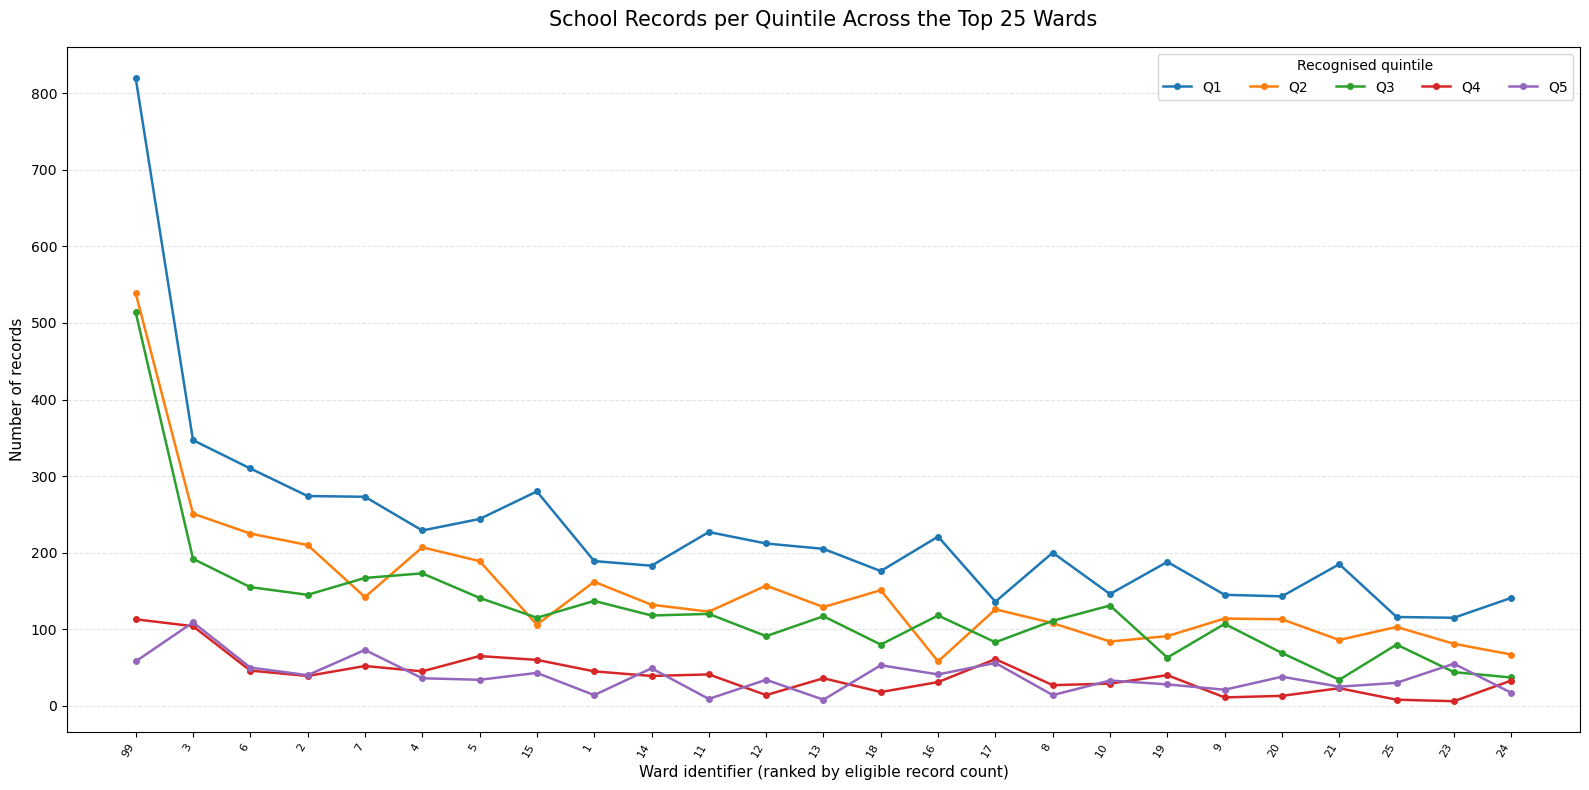


Saved: visualisation_1_schools_per_quintile_by_ward.png


In [36]:
# ============================================================
# VISUALISATION 1: RECORD COUNTS BY WARD AND QUINTILE
# ============================================================

# ------------------------------------------------------------
# 1. Prepare the plotting DataFrame
# ------------------------------------------------------------

ward_plot = pd.DataFrame({
    "ward": ward_text,
    "quintile": quintile_text
})

# Define usable values.
# This excludes missing/blank identifiers and non-standard
# quintile labels, but does not impose a ward-length rule.
ward_usable_mask = ward_plot["ward"].notna()
quintile_usable_mask = ward_plot["quintile"].isin(QUINTILES)

ward_plot["ward_usable"] = ward_usable_mask
ward_plot["quintile_usable"] = quintile_usable_mask

eligible_mask = ward_usable_mask & quintile_usable_mask

print("=" * 65)
print("VISUALISATION 1: RECORD EXCLUSIONS")
print("=" * 65)

print(f"Starting records: {len(ward_plot):,}")
print(
    "Records excluded for missing/blank ward identifier:",
    f"{(~ward_usable_mask).sum():,}"
)
print(
    "Records excluded for missing/non-standard quintile:",
    f"{(~quintile_usable_mask).sum():,}"
)
print(
    "Records excluded for either reason (unique records):",
    f"{(~eligible_mask).sum():,}"
)
print(f"Eligible records: {eligible_mask.sum():,}")

# Apply both eligibility conditions.
ward_plot = ward_plot.loc[eligible_mask, ["ward", "quintile"]].copy()

if ward_plot.empty:
    raise ValueError(
        "No eligible records are available for Visualisation 1. "
        "Check ward_id_clean and quintile_clean."
    )

# ------------------------------------------------------------
# 2. Count records per ward and quintile
# ------------------------------------------------------------

ward_counts = (
    ward_plot
    .groupby(["ward", "quintile"], observed=True)
    .size()
    .rename("record_count")
    .reset_index()
)

# Sort ward identifiers consistently using natural sorting.
# Numeric-looking identifiers sort numerically, while mixed
# identifiers sort by their text and digit segments.
def natural_sort_key(value):
    parts = re.split(r"(\d+)", str(value))
    return [
        (1, int(part)) if part.isdigit()
        else (0, part.casefold())
        for part in parts
        if part != ""
    ]

all_wards = sorted(
    ward_counts["ward"].unique().tolist(),
    key=natural_sort_key
)

# Calculate each ward's total across recognised quintiles.
ward_totals = (
    ward_counts
    .groupby("ward")["record_count"]
    .sum()
    .sort_values(ascending=False)
)

# Select the most frequently represented wards.
n_wards = min(TOP_N_WARDS, len(ward_totals))

top_wards = ward_totals.head(n_wards).index.tolist()

print(f"\nDistinct eligible wards: {len(all_wards):,}")
print(f"Wards displayed in the line plot: {n_wards:,}")

# Print the ward totals so the selection is transparent.
print("\nTop wards by eligible record count:")
print(
    ward_totals.head(n_wards)
    .rename("eligible_record_count")
    .to_frame()
)

# ------------------------------------------------------------
# 3. Create a complete ward-quintile count table
# ------------------------------------------------------------

# Reindex so that every displayed ward has Q1-Q5 columns.
# A missing ward-quintile combination is assigned a count of zero.
selected_counts = (
    ward_counts[ward_counts["ward"].isin(top_wards)]
    .pivot(index="ward", columns="quintile", values="record_count")
    .reindex(index=top_wards, columns=QUINTILES)
    .fillna(0)
    .astype(int)
)

# Keep ward order consistent with the descending ranking.
print("\nWard-quintile count table:")
display(selected_counts)

# Save the table for further analysis or inclusion in the report.
selected_counts.to_csv(
    OUTPUT_DIR / "visualisation_1_ward_quintile_counts.csv",
    index=True
)

# ------------------------------------------------------------
# 4. Plot the line chart
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(16, 8))

# Each line represents one recognised quintile.
for quintile in QUINTILES:
    ax.plot(
        range(len(selected_counts)),
        selected_counts[quintile].values,
        marker="o",
        markersize=4,
        linewidth=1.8,
        label=quintile
    )

ax.set_title(
    f"School Records per Quintile Across the Top {n_wards} Wards",
    fontsize=15,
    pad=15
)

ax.set_xlabel(
    "Ward identifier (ranked by eligible record count)",
    fontsize=11
)

ax.set_ylabel("Number of records", fontsize=11)

ax.set_xticks(range(len(selected_counts)))
ax.set_xticklabels(
    selected_counts.index.tolist(),
    rotation=60,
    ha="right",
    fontsize=8
)

ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.grid(axis="y", linestyle="--", alpha=0.35)

ax.legend(
    title="Recognised quintile",
    ncol=5,
    loc="upper right"
)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "visualisation_1_schools_per_quintile_by_ward.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print(
    "\nSaved: visualisation_1_schools_per_quintile_by_ward.png"
)

VISUALISATION 2: COORDINATE VALIDATION SUMMARY


,category,record_count
0,Starting records,199054
1,Missing or blank latitude/longitude,115420
2,Non-numeric coordinate input,0
3,Numeric coordinates outside screening bounds,15
4,Valid coordinate pairs,83619



Total coordinate-excluded records: 115,435
Coordinate-valid records with recognised quintiles: 61,957
Coordinate-valid records with missing/non-standard quintiles: 21,662

Records available for plotting: 61,957


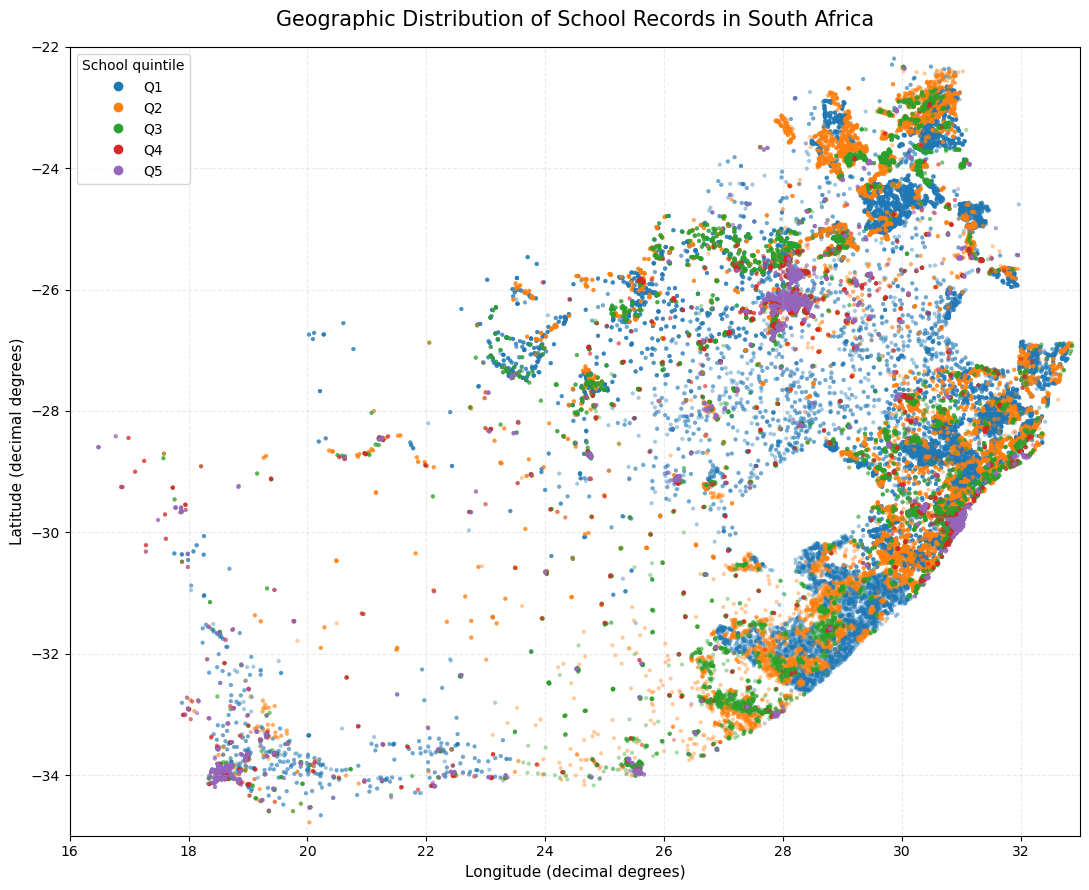


Saved: visualisation_2_school_geographic_scatter.png


In [37]:
# ============================================================
# VISUALISATION 2: GEOGRAPHIC SCATTER PLOT
# ============================================================

# ------------------------------------------------------------
# 1. Create a separate coordinate-validation DataFrame
# ------------------------------------------------------------

geo_plot = pd.DataFrame({
    "latitude_raw": df_viz["latitude_clean"],
    "longitude_raw": df_viz["longitude_clean"],
    "quintile": quintile_text
})

# Convert coordinates to numeric values without changing df_clean.
geo_plot["latitude"] = pd.to_numeric(
    geo_plot["latitude_raw"], errors="coerce"
)

geo_plot["longitude"] = pd.to_numeric(
    geo_plot["longitude_raw"], errors="coerce"
)

# Identify genuinely missing/blank coordinate inputs.
lat_missing = (
    geo_plot["latitude_raw"].isna()
    | geo_plot["latitude_raw"].astype("string").str.strip().eq("").fillna(False)
)

lon_missing = (
    geo_plot["longitude_raw"].isna()
    | geo_plot["longitude_raw"].astype("string").str.strip().eq("").fillna(False)
)

# Priority 1: at least one coordinate is missing or blank.
coordinate_missing = lat_missing | lon_missing

# Priority 2: at least one coordinate is non-numeric,
# provided neither coordinate input is missing/blank.
coordinate_nonnumeric = (
    ~coordinate_missing
    & (
        geo_plot["latitude"].isna()
        | geo_plot["longitude"].isna()
    )
)

# Only test bounds when both coordinates are numeric.
numeric_pair = (
    geo_plot["latitude"].notna()
    & geo_plot["longitude"].notna()
)

within_bounds = (
    numeric_pair
    & geo_plot["latitude"].between(LAT_MIN, LAT_MAX, inclusive="both")
    & geo_plot["longitude"].between(LON_MIN, LON_MAX, inclusive="both")
)

# Priority 3: numeric pairs outside the screening bounds.
coordinate_out_of_bounds = numeric_pair & ~within_bounds

# Accepted coordinate records.
valid_coordinates = within_bounds

# ------------------------------------------------------------
# 2. Report coordinate exclusions
# ------------------------------------------------------------

coordinate_summary = pd.DataFrame({
    "category": [
        "Starting records",
        "Missing or blank latitude/longitude",
        "Non-numeric coordinate input",
        "Numeric coordinates outside screening bounds",
        "Valid coordinate pairs"
    ],
    "record_count": [
        len(geo_plot),
        int(coordinate_missing.sum()),
        int(coordinate_nonnumeric.sum()),
        int(coordinate_out_of_bounds.sum()),
        int(valid_coordinates.sum())
    ]
})

print("=" * 65)
print("VISUALISATION 2: COORDINATE VALIDATION SUMMARY")
print("=" * 65)

display(coordinate_summary)

# Confirm that the mutually exclusive groups account for
# all records.
classified_total = (
    coordinate_missing.sum()
    + coordinate_nonnumeric.sum()
    + coordinate_out_of_bounds.sum()
    + valid_coordinates.sum()
)

assert classified_total == len(geo_plot), (
    "Coordinate categories do not account for every record."
)

print(
    f"\nTotal coordinate-excluded records: "
    f"{(~valid_coordinates).sum():,}"
)

print(
    "Coordinate-valid records with recognised quintiles:",
    f"{(valid_coordinates & geo_plot['quintile'].isin(QUINTILES)).sum():,}"
)

print(
    "Coordinate-valid records with missing/non-standard quintiles:",
    f"{(valid_coordinates & ~geo_plot['quintile'].isin(QUINTILES)).sum():,}"
)

# ------------------------------------------------------------
# 3. Keep valid coordinates and recognised quintile labels
# ------------------------------------------------------------

geo_recognised = geo_plot.loc[
    valid_coordinates & geo_plot["quintile"].isin(QUINTILES)
].copy()

print(f"\nRecords available for plotting: {len(geo_recognised):,}")

# ------------------------------------------------------------
# 4. Plot the geographic scatter plot
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 9))

# Use one consistent colour for each quintile.
quintile_colours = {
    "Q1": "tab:blue",
    "Q2": "tab:orange",
    "Q3": "tab:green",
    "Q4": "tab:red",
    "Q5": "tab:purple"
}

for quintile in QUINTILES:
    subset = geo_recognised[
        geo_recognised["quintile"] == quintile
    ]

    if not subset.empty:
        ax.scatter(
            subset["longitude"],
            subset["latitude"],
            s=9,
            alpha=0.40,
            color=quintile_colours[quintile],
            edgecolors="none",
            rasterized=True,
            label=quintile
        )

# Provide a useful message if no records are available.
if geo_recognised.empty:
    ax.text(
        0.5,
        0.5,
        "No records have both valid coordinates\n"
        "and recognised quintile labels.",
        ha="center",
        va="center",
        transform=ax.transAxes,
        fontsize=12
    )

# A custom legend ensures Q1-Q5 are explained consistently,
# even if some quintile categories contain zero plotted records.
legend_handles = [
    Line2D(
        [0], [0],
        marker="o",
        linestyle="none",
        markersize=7,
        markerfacecolor=quintile_colours[q],
        markeredgecolor="none",
        label=q
    )
    for q in QUINTILES
]

ax.legend(
    handles=legend_handles,
    title="School quintile",
    loc="best"
)

ax.set_title(
    "Geographic Distribution of School Records in South Africa",
    fontsize=15,
    pad=15
)

ax.set_xlabel("Longitude (decimal degrees)", fontsize=11)
ax.set_ylabel("Latitude (decimal degrees)", fontsize=11)

ax.set_xlim(LON_MIN, LON_MAX)
ax.set_ylim(LAT_MIN, LAT_MAX)

ax.grid(linestyle="--", alpha=0.25)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "visualisation_2_school_geographic_scatter.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("\nSaved: visualisation_2_school_geographic_scatter.png")

VISUALISATION 3: QUINTILE DISTRIBUTION SUMMARY
Total dataset records: 199,054
Records with recognised Q1-Q5 labels: 156,874
Missing/non-standard quintile records: 42,180

Counts and percentages:


,quintile,record_count,percentage_of_all_records,percentage_of_recognised_records
0,Q1,"52,626",26.44%,33.55%
1,Q2,"43,207",21.71%,27.54%
2,Q3,"35,131",17.65%,22.39%
3,Q4,"12,236",6.15%,7.80%
4,Q5,"13,674",6.87%,8.72%


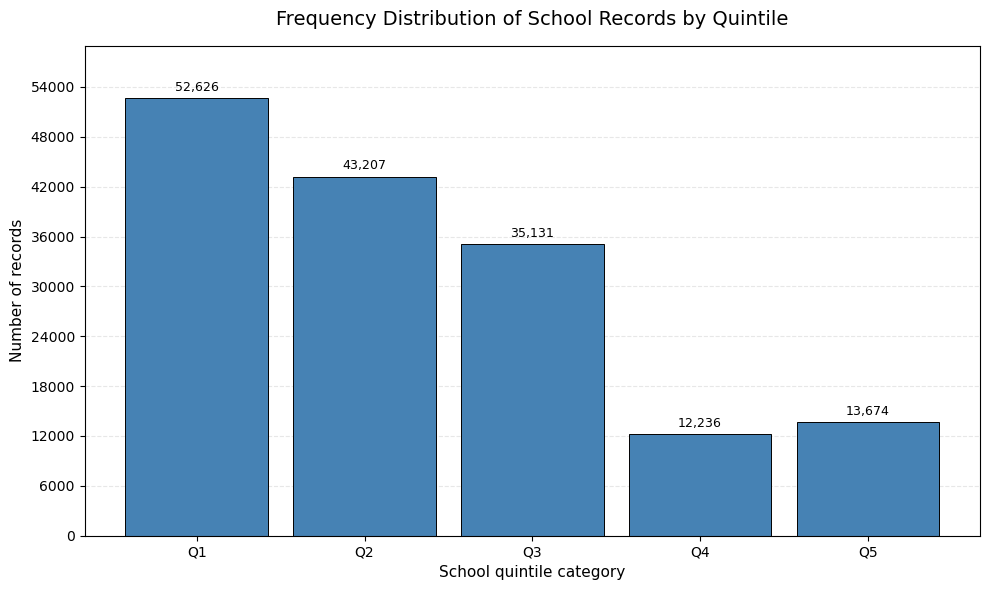


Saved: visualisation_3a_quintile_histogram_style.png


In [38]:
# ============================================================
# VISUALISATION 3A: HISTOGRAM-STYLE QUINTILE FREQUENCIES
# ============================================================

# ------------------------------------------------------------
# 1. Count recognised quintile categories
# ------------------------------------------------------------

quintile_counts = (
    quintile_text
    .value_counts()
    .reindex(QUINTILES, fill_value=0)
    .astype(int)
)

total_records = len(df_viz)
recognised_records = int(quintile_counts.sum())

missing_or_nonstandard = total_records - recognised_records

# Percentages of all dataset records.
if total_records > 0:
    percent_of_all = quintile_counts / total_records * 100
else:
    percent_of_all = pd.Series(0.0, index=QUINTILES)

# Percentages of recognised Q1-Q5 records only.
if recognised_records > 0:
    percent_of_recognised = (
        quintile_counts / recognised_records * 100
    )
else:
    percent_of_recognised = pd.Series(0.0, index=QUINTILES)

# ------------------------------------------------------------
# 2. Create and display the summary table
# ------------------------------------------------------------

quintile_summary = pd.DataFrame({
    "quintile": QUINTILES,
    "record_count": quintile_counts.reindex(QUINTILES).values,
    "percentage_of_all_records": percent_of_all.reindex(QUINTILES).values,
    "percentage_of_recognised_records": (
        percent_of_recognised.reindex(QUINTILES).values
    )
})

print("=" * 65)
print("VISUALISATION 3: QUINTILE DISTRIBUTION SUMMARY")
print("=" * 65)

print(f"Total dataset records: {total_records:,}")
print(f"Records with recognised Q1-Q5 labels: {recognised_records:,}")
print(f"Missing/non-standard quintile records: {missing_or_nonstandard:,}")

print("\nCounts and percentages:")
display(
    quintile_summary.style.format({
        "record_count": "{:,.0f}",
        "percentage_of_all_records": "{:.2f}%",
        "percentage_of_recognised_records": "{:.2f}%"
    })
)

# Save the table as a CSV file.
quintile_summary.to_csv(
    OUTPUT_DIR / "visualisation_3_quintile_distribution.csv",
    index=False
)

# ------------------------------------------------------------
# 3. Draw an adjacent-bar, histogram-style frequency plot
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    QUINTILES,
    quintile_counts.reindex(QUINTILES).values,
    width=0.85,
    color="steelblue",
    edgecolor="black",
    linewidth=0.7
)

ax.set_title(
    "Frequency Distribution of School Records by Quintile",
    fontsize=14,
    pad=15
)

ax.set_xlabel("School quintile category", fontsize=11)
ax.set_ylabel("Number of records", fontsize=11)

ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

# Add record counts above the bars.
ax.bar_label(
    bars,
    labels=[f"{value:,}" for value in quintile_counts.values],
    padding=3,
    fontsize=9
)

# Keep enough room for the labels above the tallest bar.
ax.margins(y=0.12)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "visualisation_3a_quintile_histogram_style.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("\nSaved: visualisation_3a_quintile_histogram_style.png")

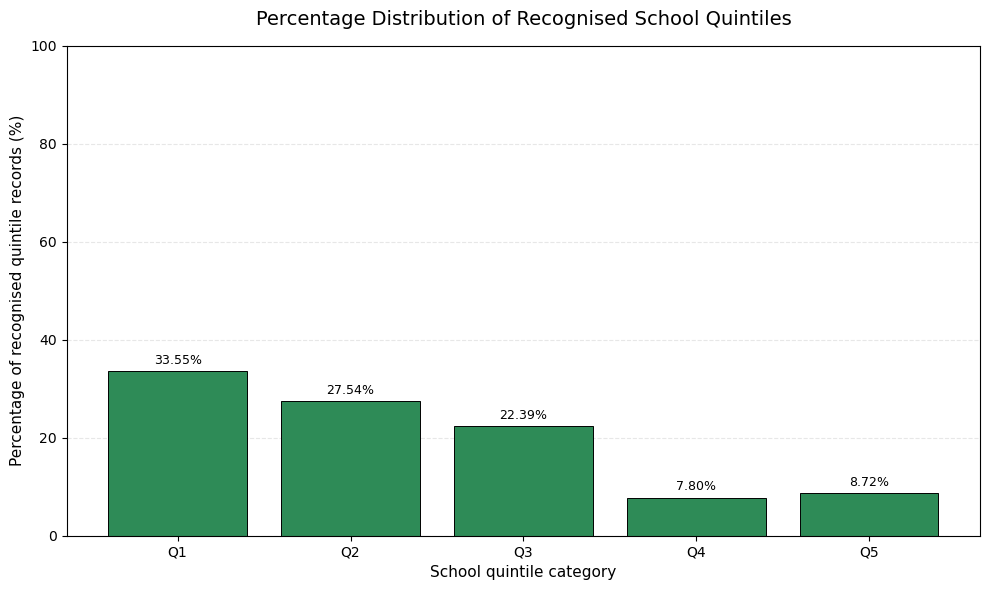


Saved: visualisation_3b_quintile_percentage_bar_chart.png


In [39]:
# ============================================================
# VISUALISATION 3B: SUPPLEMENTARY PERCENTAGE BAR CHART
# ============================================================

fig, ax = plt.subplots(figsize=(10, 6))

percentage_values = percent_of_recognised.reindex(QUINTILES).values

bars = ax.bar(
    QUINTILES,
    percentage_values,
    color="seagreen",
    edgecolor="black",
    linewidth=0.7
)

ax.set_title(
    "Percentage Distribution of Recognised School Quintiles",
    fontsize=14,
    pad=15
)

ax.set_xlabel("School quintile category", fontsize=11)
ax.set_ylabel("Percentage of recognised quintile records (%)", fontsize=11)

ax.set_ylim(0, max(100, float(np.max(percentage_values)) * 1.15))
ax.yaxis.set_major_locator(MaxNLocator(nbins=6))
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

ax.bar_label(
    bars,
    labels=[f"{value:.2f}%" for value in percentage_values],
    padding=3,
    fontsize=9
)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "visualisation_3b_quintile_percentage_bar_chart.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("\nSaved: visualisation_3b_quintile_percentage_bar_chart.png")